DATASET
   Time     Value
0     0  0.024836
1     1  0.087897
2     2  0.220874
3     3  0.356079
4     4  0.356354

MODEL PERFORMANCE
RNN Test Loss: 0.002872308250516653
LSTM Test Loss: 0.002272810088470578


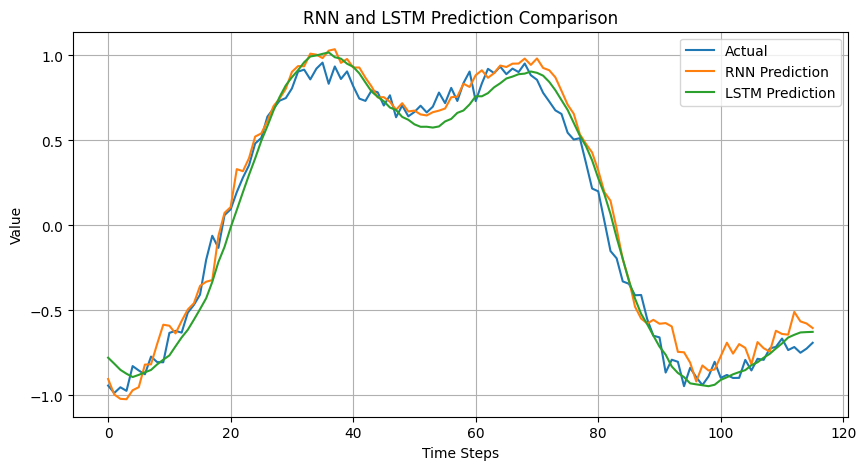

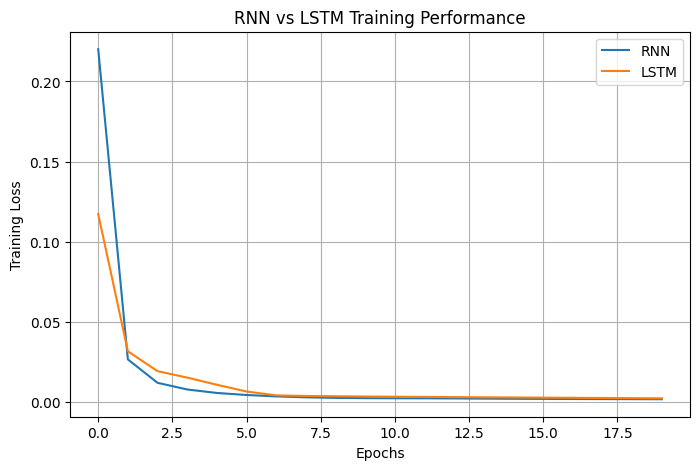


FINAL COMPARISON
  Model  Test Loss
0   RNN   0.002872
1  LSTM   0.002273


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler

np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate time-series dataset
time = np.arange(600)

values = (
    np.sin(0.05 * time)
    + 0.3 * np.sin(0.15 * time)
    + np.random.normal(0, 0.05, 600)
)

data = pd.DataFrame({
    "Time": time,
    "Value": values
})

print("DATASET")
print(data.head())

# 2. Normalize dataset
scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(
    data[["Value"]]
)

# 3. Create sequences
def create_sequences(data, steps):

    X, y = [], []

    for i in range(len(data) - steps):

        X.append(data[i:i + steps])

        y.append(data[i + steps])

    return np.array(X), np.array(y)

steps = 20

X, y = create_sequences(
    scaled_data,
    steps
)

# 4. Split dataset
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

# 5. Build RNN model
def build_rnn():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(shape=(steps, 1)),

        tf.keras.layers.SimpleRNN(
            32,
            activation="tanh"
        ),

        tf.keras.layers.Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    return model

# 6. Build LSTM model
def build_lstm():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(shape=(steps, 1)),

        tf.keras.layers.LSTM(
            32
        ),

        tf.keras.layers.Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    return model

# 7. Train RNN
rnn_model = build_rnn()

rnn_history = rnn_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

# 8. Train LSTM
lstm_model = build_lstm()

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

# 9. Evaluate models
rnn_loss = rnn_model.evaluate(
    X_test, y_test, verbose=0
)

lstm_loss = lstm_model.evaluate(
    X_test, y_test, verbose=0
)

print("\nMODEL PERFORMANCE")

print("RNN Test Loss:", rnn_loss)

print("LSTM Test Loss:", lstm_loss)

# 10. Generate predictions
rnn_predictions = rnn_model.predict(
    X_test, verbose=0
)

lstm_predictions = lstm_model.predict(
    X_test, verbose=0
)

# Convert to original scale
actual = scaler.inverse_transform(y_test)

rnn_predictions = scaler.inverse_transform(
    rnn_predictions
)

lstm_predictions = scaler.inverse_transform(
    lstm_predictions
)

# 11. Plot predictions
plt.figure(figsize=(10, 5))

plt.plot(
    actual,
    label="Actual"
)

plt.plot(
    rnn_predictions,
    label="RNN Prediction"
)

plt.plot(
    lstm_predictions,
    label="LSTM Prediction"
)

plt.title("RNN and LSTM Prediction Comparison")

plt.xlabel("Time Steps")
plt.ylabel("Value")

plt.legend()
plt.grid()

plt.show()

# 12. Compare training losses
plt.figure(figsize=(8, 5))

plt.plot(
    rnn_history.history["loss"],
    label="RNN"
)

plt.plot(
    lstm_history.history["loss"],
    label="LSTM"
)

plt.xlabel("Epochs")
plt.ylabel("Training Loss")

plt.title("RNN vs LSTM Training Performance")

plt.legend()
plt.grid()

plt.show()

# 13. Display comparison
comparison = pd.DataFrame({
    "Model": ["RNN", "LSTM"],
    "Test Loss": [rnn_loss, lstm_loss]
})

print("\nFINAL COMPARISON")
print(comparison)